# Data Visualization and Analysis

The mathematician Richard Hamming once said, “The purpose of computing is insight, not numbers,” and the best way to develop insight is often to visualize data. In this notebook we'll use `matplotlib`, the de facto standard plotting library in Python, together with the loops, functions, and conditionals we've learned so far to answer a real question about a real-looking dataset:

> **Can we trust this clinical trial data?**

Dr. Maverick has sent us the results of a clinical trial for a new arthritis drug. There are 12 files (`inflammation-01.csv` to `inflammation-12.csv`). Each file holds inflammation scores for 60 patients over 40 days. Dr. Maverick claims that inflammation rises and then falls over the course of the trial, in line with the drug taking about three weeks to work. Before we believe it, let's look at the data.

![](https://swcarpentry.github.io/python-novice-inflammation/fig/lesson-overview.svg)

### By the end of this notebook, you'll be able to:
* Create and customize plots using `matplotlib.pyplot`
* Plot multiple graphs in a single figure
* Loop over many data files using `glob`
* Write a function that checks a dataset for problems
* Combine these tools to decide whether data can be trusted

### Table of Contents
1. [Step One: Plotting tools](#one)
2. [Step Two: Look at one trial](#two)
3. [Step Three: Look at many trials](#three)
4. [Step Four: Automate the checks](#four)
5. [Step Five: Make the case](#five)

<a id="one"></a>

## Step One: Get comfortable with our plotting tools

First, let's get set up for plotting by importing the necessary tool boxes. Below, import the `pyplot` module from `matplotlib` as `plt`.

In [2]:
# Import matplotlib pyplot, our main plotting module
import matplotlib.pyplot as plt

Next we'll import `numpy` and load the first trial file. As we saw in the NumPy notebook, each row is a patient and each column is a day, so this is a two-dimensional array.

In [3]:
# Import numpy
import numpy as np

# Load the first trial
data = np.loadtxt(fname='Data/inflammation/inflammation-01.csv', delimiter=',')

# Check the shape: (patients, days)
print(data.shape)

(60, 40)


Now, we can use the `matplotlib.pyplot` module (imported as `plt` above) to plot the inflammation for a single patient.

Useful functions:
* `plt.plot()` create a plot from a list, array, pandas series, etc.
* `plt.show()` show the plot (not strictly necessary in Jupyter, necessary in other IDEs)
* `plt.xlabel()` and `plt.ylabel()` change x and y labels
* `plt.title()` add a title

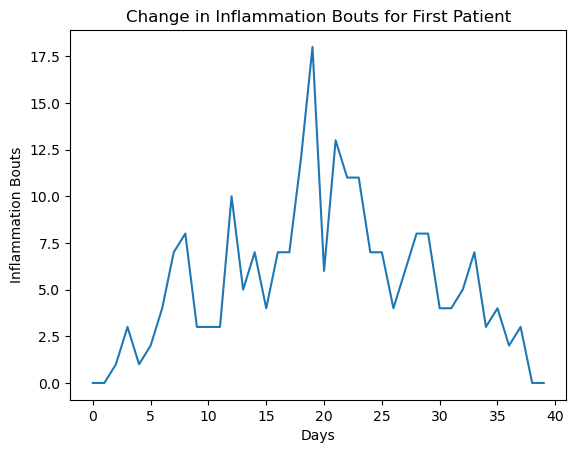

In [4]:
# 1 - Plot the data for the first patient (row 0)
plt.plot(data[0,:])

# 2 - Change plot attributes
plt.title('Change in Inflammation Bouts for First Patient')
plt.xlabel('Days')
plt.ylabel('Inflammation Bouts')

# 3 - Show the plot
plt.show()

The `plt.hist()` function works really similarly (see documentation <a href="https://matplotlib.org/api/_as_gen/matplotlib.pyplot.hist.html">here</a>).

<div class="alert alert-success">

**Task**: In the cell below:

1. Plot a histogram of *every* inflammation value in `data` (all patients, all days). Hint: `plt.hist()` wants a 1D list of values, so try `data.flatten()`.
2. Label your axes.

</div>

Text(0.5, 0, 'Days')

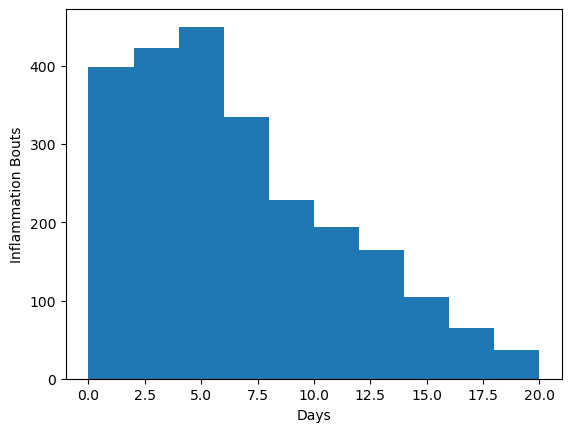

In [5]:
# Generate your plot here
plt.hist(data.flatten())
plt.ylabel('Inflammation Bouts')
plt.xlabel('Days')

We can also set up multiple subplots on the same figure using `plt.subplots()`. This also creates separate **axes** (really, separate plots) which we can access and manipulate. It's common to use the `subplots` command for easier access to axis attributes.

In [6]:
# Get information about subplots
plt.subplots?

Signature:
plt.subplots(
    nrows: 'int' = 1,
    ncols: 'int' = 1,
    *,
    sharex: "bool | Literal['none', 'all', 'row', 'col']" = False,
    sharey: "bool | Literal['none', 'all', 'row', 'col']" = False,
    squeeze: 'bool' = True,
    width_ratios: 'Sequence[float] | None' = None,
    height_ratios: 'Sequence[float] | None' = None,
    subplot_kw: 'dict[str, Any] | None' = None,
    gridspec_kw: 'dict[str, Any] | None' = None,
    **fig_kw,
) -> 'tuple[Figure, Any]'
Docstring:
Create a figure and a set of subplots.

This utility wrapper makes it convenient to create common layouts of
subplots, including the enclosing figure object, in a single call.

Parameters
----------
nrows, ncols : int, default: 1
    Number of rows/columns of the subplot grid.

sharex, sharey : bool or {'none', 'all', 'row', 'col'}, default: False
    Controls sharing of properties among x (*sharex*) or y (*sharey*)
    axes:

    - True or 'all': x- or y-axis will be shared among all subplots.
    - False

**Side Note**: We can assign two things at the same time!

In [7]:
a , b = 2 , 3
print(a)
print(b)

2
3


Below, we'll generate our figure with multiple subplots: one row, two columns.

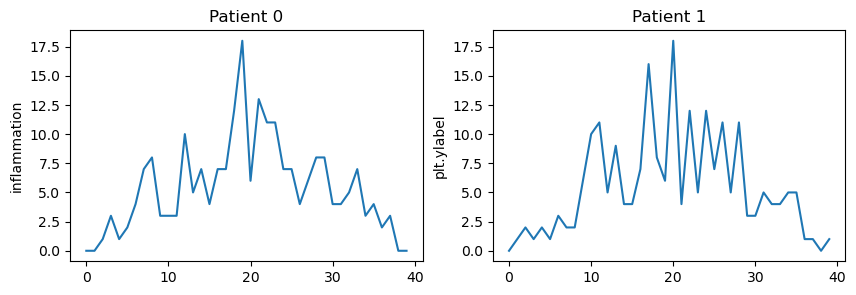

In [8]:
# 1 - Generate a figure with subplots
fig, ax = plt.subplots(1, 2, figsize=(10, 3))


# 2 - Plot patient 0 on the first axis, [0]
ax[0].plot(data[0])

# 3 - Update axis parameters
ax[0].set_ylabel('inflammation')
ax[0].set_title('Patient 0')

# 4 - Plot patient 1 on the second axis, [1]
ax[1].plot(data[1])
ax[1].set_ylabel('inflammation')
ax[1].set_title('Patient 1')

# 5 - Update general plot parameters
plt.ylabel('plt.ylabel')  # Compare what this does versus ax.set_ylabel. Which axis got the label?

plt.show()

<a id="two"></a>

## Step Two: Look at one trial

A single patient's line is hard to interpret. Because our data is two-dimensional, we can visualize *all* the patients at once as a heatmap using the `imshow` function.

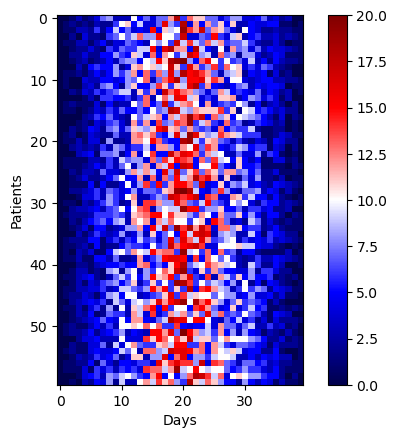

In [9]:
# Display data as image
image = plt.imshow(data, cmap='seismic')

plt.colorbar()         # Add color bar
plt.xlabel('Days')     # Add x label
plt.ylabel('Patients') # Add y label
plt.show()

Each row in the heat map corresponds to a patient in the clinical trial dataset, and each column corresponds to a day. Blue pixels represent low values, while yellow pixels represent high values. As we can see, the general level of inflammation for the patients rises and falls over the 40-day period, just as Dr. Maverick claimed.

To summarize the whole trial in a single line, let's compute the average inflammation on each day across all patients. (Hint: which `axis` do we want to average over?)

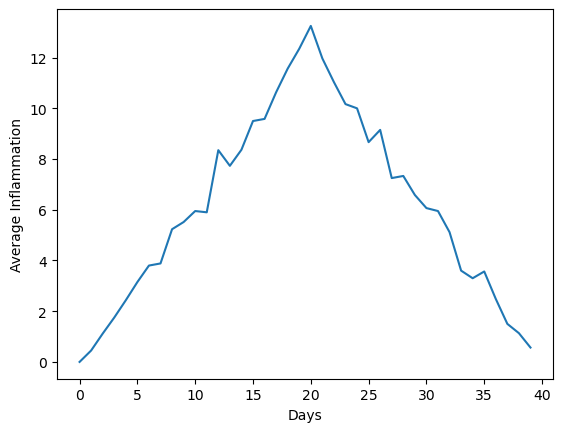

In [10]:
# Compute average inflammation per day

ave_inflammation = data.mean(axis=0)

plt.plot(ave_inflammation)
plt.xlabel('Days')
plt.ylabel('Average Inflammation')
plt.show()

The result is a reasonably smooth rise and fall, in line with the idea that this medication takes three weeks to take effect. But a good data scientist doesn't just consider the average of a dataset, so let's have a look at two other statistics.

<div class="alert alert-success">

**Task**: Using the <code>np.min</code> and <code>np.max</code> functions we've seen before, and the <code>plot</code> function you learned above, plot the <b>maximum</b> and <b>minimum</b> inflammation over time. Plot these in subplots, side by side with the mean: you should have three plots in a row: mean, max, and min.

</div>

(40,) (40,)


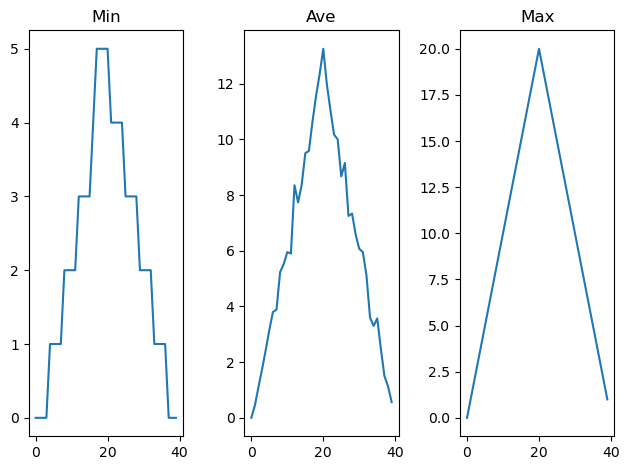

In [11]:
# Calculate average, min, max
min_inflammation = np.min(data, axis=0)
max_inflammation = np.max(data, axis=0)

# Check the data shape
print(min_inflammation.shape, max_inflammation.shape)

# Set up the figure with subplots
fig, ax = plt.subplots(1,3)

# Plot on each axis
ax[0].plot(min_inflammation)
ax[0].set_title('Min')

ax[1].plot(ave_inflammation)
ax[1].set_title('Ave')

ax[2].plot(max_inflammation)
ax[2].set_title('Max')

fig.tight_layout()

plt.show()

You can save your figure using `plt.savefig('inflammation.png')`. The call to `savefig` stores the plot as a graphics file. This can be a convenient way to store your plots for use in other documents, web pages etc. The graphics format is automatically determined by Matplotlib from the file name ending we specify; here PNG from ‘inflammation.png’. Matplotlib supports many different graphics formats, including SVG, PDF, and JPEG.

One catch: call `savefig` *before* `plt.show()`, or you may save a blank figure.

<a id="three"></a>

## Step Three: Look at many trials

One file looks a little odd, but we have twelve. We need a way to get a list of all the files in our data directory whose names start with `inflammation-` and end with `.csv`. The following library will help us:

In [12]:
import glob

The `glob` library ([Documentation](https://docs.python.org/3/library/glob.html)) contains a function, also called `glob`, that finds files and directories whose names match a pattern. We provide those patterns as strings: the character `*` matches zero or more characters, while `?` matches any one character. We can use this to get the names of all the inflammation CSV files in our data directory:

In [13]:
print(glob.glob('Data/inflammation/inflammation*.csv'))

['Data/inflammation/inflammation-11.csv', 'Data/inflammation/inflammation-07.csv', 'Data/inflammation/inflammation-09.csv', 'Data/inflammation/inflammation-10.csv', 'Data/inflammation/inflammation-08.csv', 'Data/inflammation/inflammation-01.csv', 'Data/inflammation/inflammation-06.csv', 'Data/inflammation/inflammation-05.csv', 'Data/inflammation/inflammation-02.csv', 'Data/inflammation/inflammation-03.csv', 'Data/inflammation/inflammation-04.csv', 'Data/inflammation/inflammation-12.csv']


As this example shows, `glob.glob`'s result is a list of file paths in arbitrary order. This means we can loop over it to do something with each filename in turn. If we want to start by analyzing just the first three files in alphabetical order, we can use the `sort` method on the `glob.glob` output:

In [14]:
filenames = glob.glob('Data/inflammation/inflammation*.csv') #
filenames.sort()
filenames

['Data/inflammation/inflammation-01.csv',
 'Data/inflammation/inflammation-02.csv',
 'Data/inflammation/inflammation-03.csv',
 'Data/inflammation/inflammation-04.csv',
 'Data/inflammation/inflammation-05.csv',
 'Data/inflammation/inflammation-06.csv',
 'Data/inflammation/inflammation-07.csv',
 'Data/inflammation/inflammation-08.csv',
 'Data/inflammation/inflammation-09.csv',
 'Data/inflammation/inflammation-10.csv',
 'Data/inflammation/inflammation-11.csv',
 'Data/inflammation/inflammation-12.csv']

Now, we'll loop through the first three files and plot the mean, max, and min for each.

Data/inflammation/inflammation-01.csv


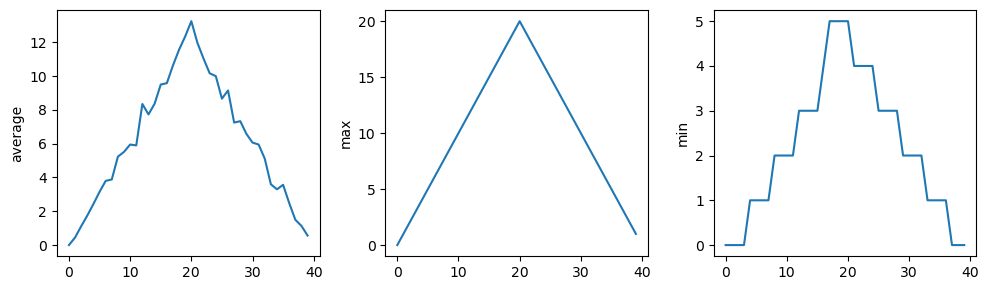

Data/inflammation/inflammation-02.csv


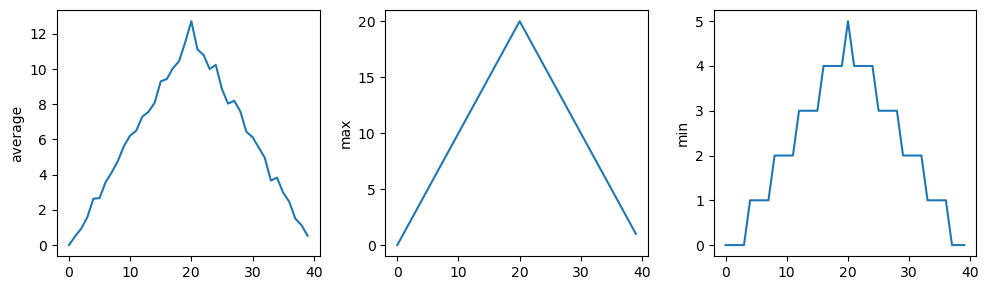

Data/inflammation/inflammation-03.csv


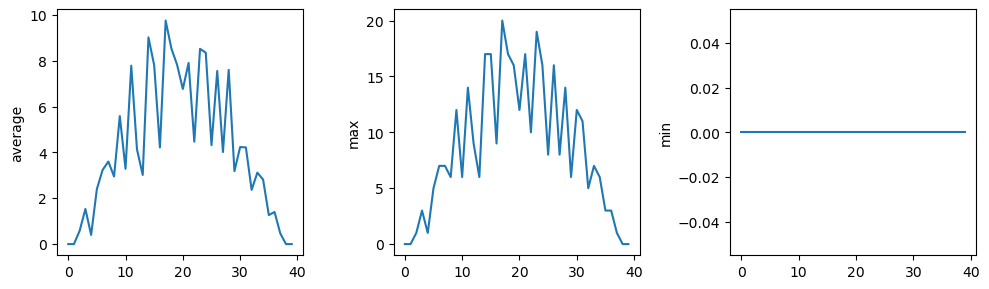

In [15]:
first_three_files = filenames[0:3]                      # Step 1: Slice out the first 3 file paths from the list filenames
                                                        # and assign to variable first_three_files

for filename in first_three_files:                      # Step 2: Create a for loop over the list first_three_files, and
                                                        # iteratively assign its elements to the loop variable filename

    print(filename)

    data = np.loadtxt(fname=filename, delimiter=',')    # Step 3: Load in the data associated with each filename, and assign it to
                                                        # the variable data

    fig, ax = plt.subplots(1, 3, figsize=(10.0, 3.0))   # Step 4: Create a figure with one row of three subplots. Set figure size to
                                                        # (10.0, 3.0)

    ax[0].set_ylabel('average')                         # Step 5: Set the label for the y-axis to say 'average' for subplot
                                                        # at axis-0 (1st column in each row of sub plots)
    ax[0].plot(np.mean(data, axis=0))

    ax[1].set_ylabel('max')
    ax[1].plot(np.max(data, axis=0))

    ax[2].set_ylabel('min')
    ax[2].plot(np.min(data, axis=0))

    fig.tight_layout()
    plt.show()

**Discuss with a neighbor**:
* What is happening in each step of the code above?
* How similar are the first two files to each other?
* What is different about the third file?
* Does anything in these plots make you uneasy about the claim that the drug works?

A heatmap of the third file might help.

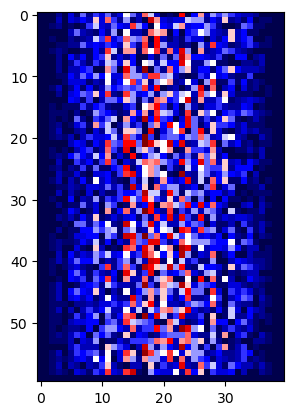

In [16]:
# Load data for the third data file (filenames[2])
third_data = np.loadtxt(filenames[2], delimiter=',')
# Plot heatmap, with a colorbar and axis labels
plt.imshow(third_data, cmap='seismic')

<a id="four"></a>

## Step Four: Automate the checks

Spotting problems by eye works for three files, but it doesn't scale to a hundred, and it isn't repeatable. Let's turn the things that bothered us into code, using conditionals.

🚩 **Red flag 1.** The maximum daily inflammation raised exactly one unit a day. Instead of checking every single day, let's merely check whether the maximum inflammation at the beginning (day 0) and in the middle (day 20) of the study equal the corresponding day numbers:

```python
max_inflammation_0 = np.max(data, axis=0)[0]
max_inflammation_20 = np.max(data, axis=0)[20]

if max_inflammation_0 == 0 and max_inflammation_20 == 20:
    print('Suspicious looking maxima!')
```

🚩 **Red flag 2.** The daily minimum was zero on every day (the sum of the daily minima is zero):

```python
if np.sum(np.min(data, axis=0)) == 0:
    print('Minima add up to zero!')
```

🚩 **Red flag 3.** One patient never had any flare-ups at all, so their maximum over the whole trial is zero (perhaps they don't even have arthritis):

```python
if np.any(np.max(data, axis=1) == 0):
    print('Patient with no flare-ups!')
```

Notice that these are three separate `if` statements, not an `if`/`elif`/`else` chain. A file could have more than one problem, and we want to hear about all of them.

<div class="alert alert-success">

**Task**: Using the code above, write a function called <code>check_data</code> which takes in a filename and checks the file for each of the three red flags. Rather than printing, your function should <b>return a list</b> of the problems it found, using exactly these messages: <code>'Suspicious looking maxima!'</code>, <code>'Minima add up to zero!'</code>, and <code>'Patient with no flare-ups!'</code>. If it finds nothing, it should return an empty list.

</div>

In [17]:
def check_data(filename):
    """Return a list of problems found in the inflammation data in filename."""

    # Load the data
    data = np.loadtxt(filename, delimiter=',')

    # Make an empty list to collect problems
    problems = []

    # Check 1: suspicious maxima
    max_inflammation_0 = np.max(data, axis=0)[0]
    max_inflammation_20 = np.max(data, axis=0)[20]
    if max_inflammation_0 == 0 and max_inflammation_20 == 20:
        print('Suspicious looking maxima!')
        problems.append('Suspicious looking maxima!')

    # Check 2: minima add up to zero
    if np.sum(np.min(data, axis=0)) == 0:
        print('Minima add up to zero!')
        problems.append('Minima add up to zero!')
    

    # Check 3: patient with no flare-ups
    if np.any(np.max(data, axis=1) == 0):
        print('Patient with no flare-ups!')
        problems.append('Patient with no flare-ups!')

    return problems

Once we have our function, we can run it on every dataset!

In [18]:
for filename in filenames:
    print(filename, check_data(filename), '\n')

Suspicious looking maxima!
Data/inflammation/inflammation-01.csv ['Suspicious looking maxima!'] 

Suspicious looking maxima!
Data/inflammation/inflammation-02.csv ['Suspicious looking maxima!'] 

Minima add up to zero!
Patient with no flare-ups!
Data/inflammation/inflammation-03.csv ['Minima add up to zero!', 'Patient with no flare-ups!'] 

Suspicious looking maxima!
Data/inflammation/inflammation-04.csv ['Suspicious looking maxima!'] 

Suspicious looking maxima!
Data/inflammation/inflammation-05.csv ['Suspicious looking maxima!'] 

Suspicious looking maxima!
Data/inflammation/inflammation-06.csv ['Suspicious looking maxima!'] 

Suspicious looking maxima!
Data/inflammation/inflammation-07.csv ['Suspicious looking maxima!'] 

Minima add up to zero!
Patient with no flare-ups!
Data/inflammation/inflammation-08.csv ['Minima add up to zero!', 'Patient with no flare-ups!'] 

Suspicious looking maxima!
Data/inflammation/inflammation-09.csv ['Suspicious looking maxima!'] 

Suspicious looking m

**Discuss with a neighbor**: How many files pass all three checks? Does that match what you expected? What does this tell you about the whole set of trials?

We noticed earlier that the third file looks odd. But is it possible that some of these files are the *same* data? If so, a perfect copy would be a pretty strong sign that something is wrong.

<div class="alert alert-success">

**Task**: Find out which files, if any, contain identical data.

1. Load every file into the list <code>all_data</code>.
2. Compare every pair of files. <code>np.array_equal(a, b)</code> returns <code>True</code> if two arrays are identical.
3. Print the names of each pair of identical files.

</div>

In [19]:
# Load every file into a list
all_data = []
for filename in filenames:
    all_data.append(np.loadtxt(filename, delimiter=','))

# Compare every pair of files (i < j, so we don't compare a file to itself or repeat pairs)
for i in range(len(all_data)):
    for j in range(i + 1, len(all_data)):
        if np.array_equal(all_data[i], all_data[j]):
            print(filenames[i], filenames[j])


Data/inflammation/inflammation-03.csv Data/inflammation/inflammation-08.csv
Data/inflammation/inflammation-03.csv Data/inflammation/inflammation-11.csv
Data/inflammation/inflammation-08.csv Data/inflammation/inflammation-11.csv


<a id="five"></a>

## Step Five: Make the case

After spending some time investigating the heat maps, statistical plots, and automated checks, we gain some insight into the twelve clinical trial datasets. They appear to fall into two categories:

1. Seemingly “ideal” datasets that agree excellently with Dr. Maverick's claims, but display suspicious maxima.
2. “Noisy” datasets that only somewhat agree with Dr. Maverick's claims, show data collection issues, and even include an unsuitable candidate who made it into the clinical trial. Some of these are identical down to the last value.

Armed with this information, we confront Dr. Maverick about the suspicious data and duplicated files.

<img src="https://c.tenor.com/Pkj5t7gMBoIAAAAC/scrunch-suspicious.gif" alt="gif">

Dr. Maverick confesses that they fabricated the clinical data after they found out that the initial trial suffered from a number of issues, including unreliable data-recording and poor participant selection. They created fake data to prove their drug worked, and when we asked for more data they tried to generate more fake datasets, as well as throwing in the original poor-quality dataset a few times to try and make all the trials seem a bit more “realistic”.

Congratulations! We've investigated the inflammation data and proven that the datasets have been synthetically generated. Now we need to show our evidence to someone who wasn't in this room. A good figure can do that in a single glance.

<div class="alert alert-success">

**Task**: Make a two-panel “evidence” figure showing <b>every</b> file at once.

1. Left panel: the daily <b>maximum</b> for every file. Right panel: the daily <b>minimum</b> for every file.
2. Add axis labels and a title to each panel.

</div>

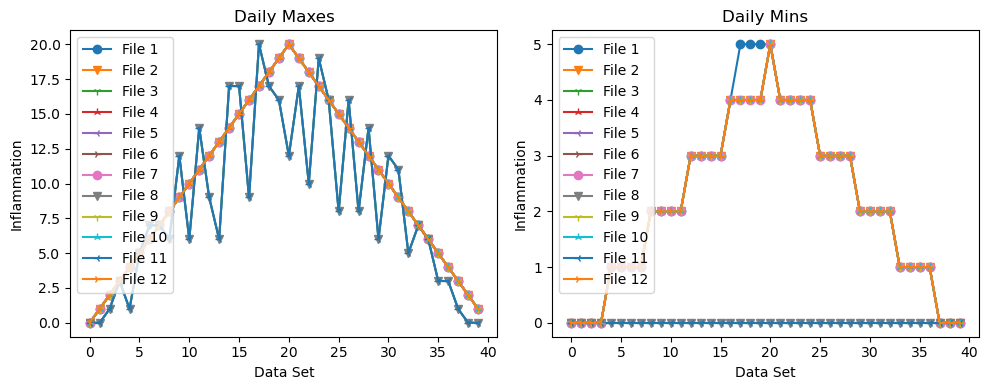

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
###--- For Quality Checks; Not required for solution ---###
file_id = 0
legend_list = []
marker_list = ['o', 'v', '1', '2','3', '4']
###-----------------------------------------------------###

for filename in filenames:
    ###--- For Quality Checks; Not required for solution ---###
    marker_id = file_id % 6
    marker = marker_list[marker_id]
    file_id += 1
    legend_name = "File " + str(file_id)
    legend_list.append(legend_name)
    ###-----------------------------------------------------###
    data = np.loadtxt(fname=filename, delimiter=',')

    # Plot the daily max on ax[0] and the daily min on ax[1]
    ax[0].plot(np.max(data, axis=0), marker=marker)
    ax[1].plot(np.min(data, axis=0), marker=marker)


# Add labels and titles
ax[0].set_title('Daily Maxes')
ax[0].set_xlabel('Data Set')
ax[0].set_ylabel('Inflammation')
ax[0].legend(legend_list)

ax[1].set_title('Daily Mins')
ax[1].set_xlabel('Data Set')
ax[1].set_ylabel('Inflammation')
ax[1].legend(legend_list)


fig.tight_layout()

# Save and show
plt.savefig('Inflammation_Comparison.png')
plt.show()

Nicely done! Look at what the figure shows: the maxima of the fabricated files lie exactly on top of each other, while the original data is messy and does something quite different. You started with a pile of CSV files and finished with a figure, produced by code, that anyone can re-run on the next batch of data.

<hr>

## About this notebook
This notebook includes data and code from [this notebook](https://swcarpentry.github.io/python-novice-inflammation/02-numpy/index.html) from the Software Carpentries and is licensed under a CC-BY-40 license (2018-2021):

> Azalee Bostroem, Trevor Bekolay, and Valentina Staneva (eds):
"Software Carpentry: Programming with Python."  Version 2016.06, June
2016, https://github.com/swcarpentry/python-novice-inflammation,
10.5281/zenodo.57492.